In [1]:
import pandas as pd
df= pd.read_csv('sales_data.csv', encoding='unicode_escape')


In [2]:
df.head()

,ORDERNUMBER,QUANTITYORDERED,PRICEEACH,ORDERLINENUMBER,SALES,ORDERDATE,STATUS,QTR_ID,MONTH_ID,YEAR_ID,...,ADDRESSLINE1,ADDRESSLINE2,CITY,STATE,POSTALCODE,COUNTRY,TERRITORY,CONTACTLASTNAME,CONTACTFIRSTNAME,DEALSIZE
0,10107,30,95.70,2,2871.00,2/24/2003 0:00,Shipped,1,2,2003,...,897 Long Airport Avenue,NaN,NYC,NY,10022,USA,NaN,Yu,Kwai,Small
1,10121,34,81.35,5,2765.90,5/7/2003 0:00,Shipped,2,5,2003,...,59 rue de l'Abbaye,NaN,Reims,NaN,51100,France,EMEA,Henriot,Paul,Small
2,10134,41,94.74,2,3884.34,7/1/2003 0:00,Shipped,3,7,2003,...,27 rue du Colonel Pierre Avia,NaN,Paris,NaN,75508,France,EMEA,Da Cunha,Daniel,Medium
3,10145,45,83.26,6,3746.70,8/25/2003 0:00,Shipped,3,8,2003,...,78934 Hillside Dr.,NaN,Pasadena,CA,90003,USA,NaN,Young,Julie,Medium
4,10159,49,100.00,14,5205.27,10/10/2003 0:00,Shipped,4,10,2003,...,7734 Strong St.,NaN,San Francisco,CA,NaN,USA,NaN,Brown,Julie,Medium


In [3]:
df= df[["QUANTITYORDERED", "PRICEEACH", "SALES"]]

In [4]:
df.nunique()

QUANTITYORDERED      58
PRICEEACH          1016
SALES              2763
dtype: int64

In [5]:
df.isna().sum()

QUANTITYORDERED    0
PRICEEACH          0
SALES              0
dtype: int64

In [8]:
from sklearn.preprocessing import StandardScaler
scaler= StandardScaler()
X_scaled= scaler.fit_transform(df)

In [14]:
from sklearn.cluster import KMeans
inertia=[]
K= range(2,20)
for k in K:
    model= KMeans(n_clusters=k, random_state=42)
    model.fit(X_scaled)
    nowi= model.inertia_
    inertia.append(nowi)


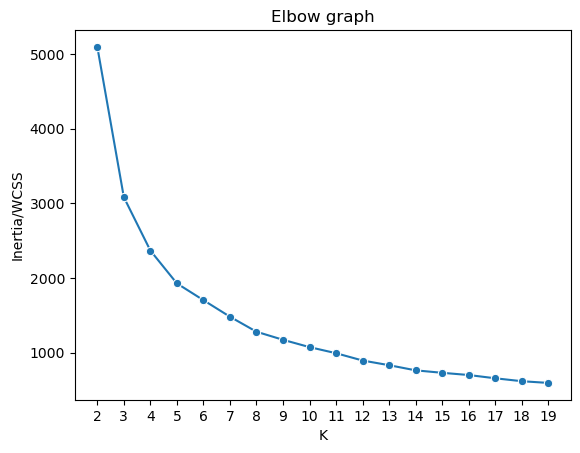

In [17]:
import matplotlib.pyplot as plt
import seaborn as sns
sns.lineplot(x=K, y=inertia, marker='o')
plt.xticks(K)
plt.title("Elbow graph")
plt.xlabel("K")
plt.ylabel("Inertia/WCSS")
plt.show()

In [33]:
optimal_k=4
model= KMeans(n_clusters=optimal_k, random_state=42)
model.fit(X_scaled)
df['class']= model.predict(X_scaled)

In [21]:
df.nunique()

QUANTITYORDERED      58
PRICEEACH          1016
SALES              2763
class                 4
dtype: int64

In [22]:
model.cluster_centers_

array([[ 0.88837014, -0.9081365 , -0.38422378],
       [ 0.89862134,  0.76500597,  1.29856015],
       [-0.72804963, -1.31000158, -1.07006862],
       [-0.7480042 ,  0.63653603, -0.17974302]])

<Axes: >

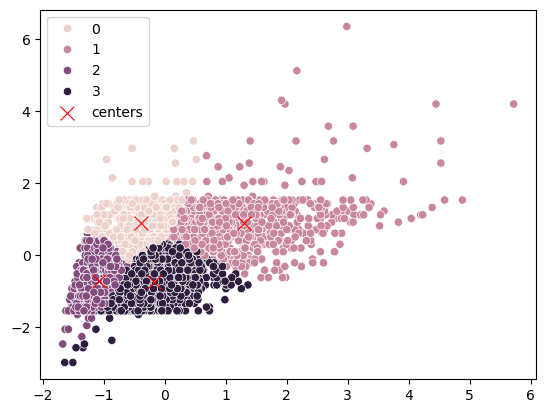

In [38]:
sns.scatterplot(x=X_scaled[:,2], y=X_scaled[:,0], hue=df['class'])
sns.scatterplot(x=model.cluster_centers_[:,2], y=model.cluster_centers_[:,0], marker='x', color='red', s=100, label='centers')